In [1]:
import os
PROJECT = "/Users/alice/Projects/nn-optimization-project"
os.chdir(PROJECT)
print(os.getcwd())

/Users/alice/Projects/nn-optimization-project


In [2]:
import torchvision as tv
import matplotlib.pyplot as plt

In [3]:
train_full = tv.datasets.CIFAR10(root="data", train=True, download=True)
test = tv.datasets.CIFAR10(root="data", train=False, download=True)

In [4]:
print(len(train_full),
len(test),
len(train_full.classes))

50000 10000 10


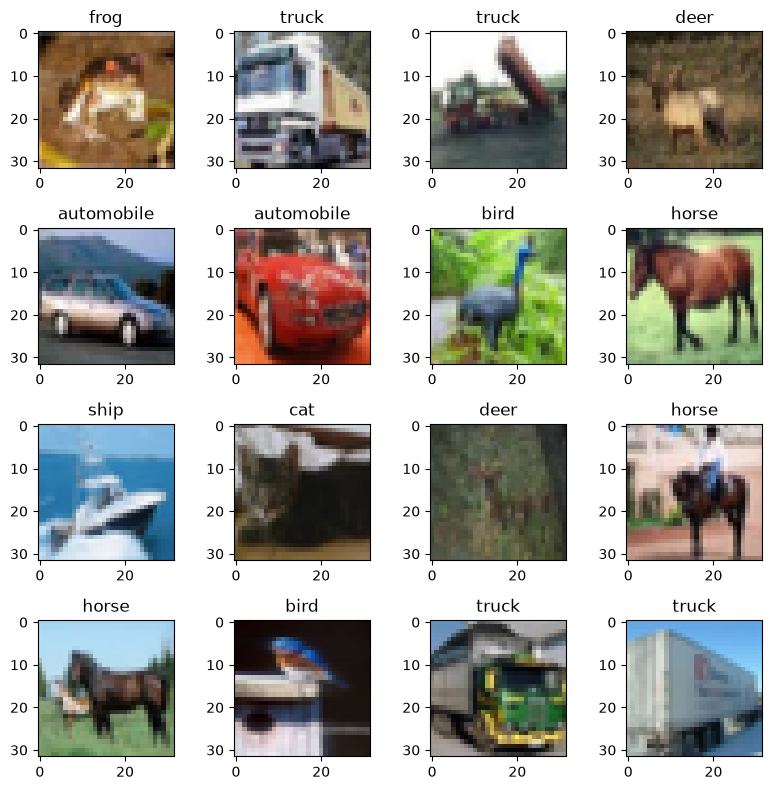

In [5]:
fig, axes = plt.subplots(4,4, figsize=(8, 8))
for i in range(16):
    img, label = train_full[i]
    ax = axes.flat[i]
    ax.imshow(img)
    ax.set_title(train_full.classes[label])

plt.tight_layout()
plt.savefig("figures/cifar_examples.png", dpi=150)
plt.show()

In [6]:
import collections
counts = collections.Counter(train_full.targets)

for label, n in sorted(counts.items()):
    print(f"{label} {train_full.classes[label]:<12} {n}")

0 airplane     5000
1 automobile   5000
2 bird         5000
3 cat          5000
4 deer         5000
5 dog          5000
6 frog         5000
7 horse        5000
8 ship         5000
9 truck        5000


***Phase 2***

In [7]:
data = train_full.data / 255
print(data.shape)   # (50000, 32, 32, 3)

(50000, 32, 32, 3)


In [8]:
mean = data.mean(axis=(0, 1, 2))
std = data.std(axis=(0, 1, 2))
print(mean, std)

[0.49139968 0.48215841 0.44653091] [0.24703223 0.24348513 0.26158784]


In [9]:
CIFAR_MEAN = (0.49139968, 0.48215841, 0.44653091)
CIFAR_STD = (0.24703223, 0.24348513, 0.26158784)

In [10]:
transform = tv.transforms.Compose([
    tv.transforms.ToTensor(),
    tv.transforms.Normalize(mean=CIFAR_MEAN, std=CIFAR_STD),
])
ds = tv.datasets.CIFAR10("data", train=True, download=True,transform=transform)
x, y = ds[0]
print(x.shape, x.dtype, x.min().item(), x.max().item())

torch.Size([3, 32, 32]) torch.float32 -1.9892128705978394 2.0945773124694824


In [11]:
from src.data import get_transforms

train_tf = get_transforms(train=True)
eval_tf = get_transforms(train=False)
print(train_tf)
print(eval_tf)

Compose(
    RandomCrop(size=(32, 32), padding=4)
    RandomHorizontalFlip(p=0.5)
    ToTensor()
    Normalize(mean=(0.49139968, 0.48215841, 0.44653091), std=(0.24703223, 0.24348513, 0.26158784))
)
Compose(
    ToTensor()
    Normalize(mean=(0.49139968, 0.48215841, 0.44653091), std=(0.24703223, 0.24348513, 0.26158784))
)


***PHASE 3***

In [12]:
import torch
from torch.utils.data import Subset
g = torch.Generator().manual_seed(42)
perm = torch.randperm(50000, generator=g).tolist()

In [13]:
train_aug = tv.datasets.CIFAR10(root="data", train=True, transform=get_transforms(train=True))
train_eval = tv.datasets.CIFAR10(root="data", train=True, transform=get_transforms(train=False))

In [14]:
train_idx = perm[:45_000]
val_idx = perm[45_000:]

In [15]:
train_set = Subset(train_aug, train_idx)   # with augmentering
val_set = Subset(train_eval, val_idx)      # without augmentering

In [16]:
print(len(train_set), len(val_set))          # 45000 5000
print(len(set(train_idx) & set(val_idx)))    # 0, no image in both
print(val_idx[:5])                           # same 5 numbers eveytime we run

45000 5000
0
[17408, 40845, 3378, 22188, 44921]


***PHASE 4***

In [17]:
from src.data import get_loaders

In [18]:
train_loader, val_loader, test_loader = get_loaders(128)
print(len(train_loader), len(val_loader), len(test_loader))   # 352 40 79

352 40 79


***PHASE 5***

In [19]:
from src.models import SimpleCNN
model = SimpleCNN()
x = torch.randn(8, 3, 32, 32)
print(model.features(x).shape)   # torch.Size([8, 128, 4, 4])

torch.Size([8, 128, 4, 4])


In [20]:
model = SimpleCNN()
x = torch.randn(8, 3, 32, 32)
print(model(x).shape)                               # torch.Size([8, 10])
print(sum(p.numel() for p in model.parameters()))   # 620810

torch.Size([8, 10])
620810


In [21]:
from src.models import build_model
model = build_model("simple_cnn")
print(model(torch.randn(8, 3, 32, 32)).shape)   # torch.Size([8, 10])
build_model("fel_namn")                          # ska ge ValueError

torch.Size([8, 10])


ValueError: Okänd modell: fel_namn

***PHASE 6***

In [22]:
from src.train import train_one_epoch, evaluate
from src.data import get_loaders
from src.models import build_model
from src.utils import set_seed, get_device
import torch, torch.nn as nn, time

set_seed(42)
device = get_device()
train_loader, val_loader, test_loader = get_loaders(128, num_workers=0)
model = build_model("simple_cnn").to(device)
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=0.05)

t0 = time.perf_counter()
loss, train_acc = train_one_epoch(model, train_loader, optimizer, criterion, device)
val_acc = evaluate(model, val_loader, device)
print(f"loss {loss:.3f} | train {train_acc:.1f} % | val {val_acc:.1f} % | {time.perf_counter() - t0:.0f} s")

Träning:   0%|          | 0/352 [00:00<?, ?it/s]

loss 1.691 | train 44.5 % | val 57.3 % | 4 s


***PHASE 8***

In [23]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("results/train_simple_cnn.csv")
df.head()

,epoch,train_loss,train_acc,val_acc,lr,epoch_time_s
0,1,1.6914,44.53,57.26,0.001000,4.4
1,2,1.4214,59.12,63.60,0.000997,4.2
2,3,1.3317,63.84,67.88,0.000989,4.2
3,4,1.2746,66.80,71.30,0.000976,4.2
4,5,1.2352,68.78,70.68,0.000957,4.2


ValueError: not enough values to unpack (expected 3, got 2)

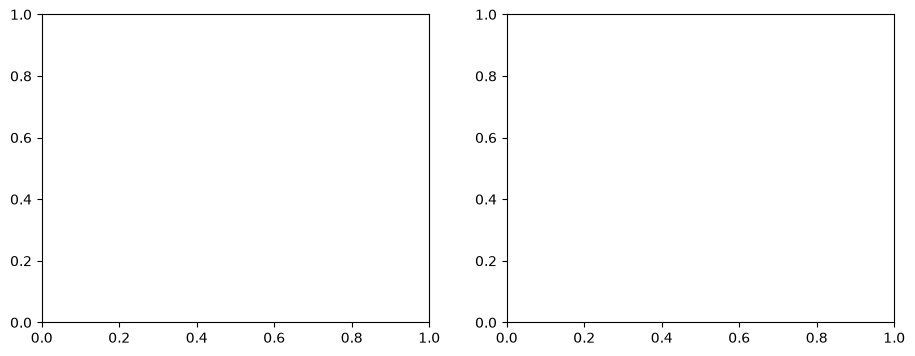

In [36]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.plot(df["epoch"], df["train_loss"], marker="o", markersize=3, label="Training")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss (cross-entropy)")
ax1.set_title("Training loss")
ax1.grid(alpha=0.3)
ax1.legend()
ax2.plot(df["epoch"], df["train_acc"], marker="o", markersize=3, label="Training")
ax2.plot(df["epoch"], df["val_acc"], marker="o", markersize=3, label="Validation")
ax2.set_xlabel("Epok")
ax2.set_ylabel("Accuracy (%)")
ax2.set_title("Accuracy")
ax2.grid(alpha=0.3)
best = df["val_acc"].idxmax()
best_epoch = df.loc[best, "epoch"]
best_val = df.loc[best, "val_acc"]

ax2.axvline(best_epoch, color="gray", linestyle="--", alpha=0.6)
ax2.annotate(f"Best: {best_val:.2f} % (epoch {best_epoch})",
             xy=(best_epoch, best_val), xytext=(best_epoch - 14, best_val - 8),
             arrowprops=dict(arrowstyle="->", color="gray"))
ax2.legend()
fig.suptitle("SimpleCNN in CIFAR-10 (30 epochs, M5 Pro, MPS) – test 83,56 %")
fig.tight_layout()
fig.savefig("figures/train_simple_cnn.png", dpi=200)
fig.savefig("figures/train_simple_cnn.pdf")
plt.show()